# Sujet hors liste (jeu Student Performance) : prédire la note finale de portugais pour cibler le soutien scolaire avant toute évaluation

**Nom et prénom :** Asmaa Makdoud    **Code Apogée :** 23009190    **Groupe :** Finance 3 (FIN)    **Filière :** S7 FIN    **Date :** 24/11/2026

**Dépôt GitHub :** https://github.com/identifiant/23009190-Makdoud-Finance3

## 1. Sujet et problématique
- **Intérêt du sujet** : un établissement (ou un ministère) dispose d'un budget limité de soutien scolaire (cours payants, tutorat). Les décisions d'allocation se prennent au début de l'année, avant la moindre note. Prédire la note finale attendue d'un élève à partir de son profil permet de classer les élèves par risque d'échec et de répartir ce budget là où le rendement attendu est le plus fort. C'est un problème de finance de l'éducation : affecter une ressource rare à partir d'une prévision.
- **Problématique** : à partir des seules caractéristiques connues à la rentrée (profil familial, habitudes, historique d'échecs, absences), un modèle d'apprentissage prévoit-il la note finale G3 (sur 20) d'un élève de portugais mieux qu'une règle naïve ?
- **Objectif mesurable** : RMSE du modèle sur le jeu de test **inférieure d'au moins 10 % à celle de la référence naïve** (moyenne de G3 sur l'apprentissage). Seuil de 10 % repris de l'exemple de l'énoncé, fixé avant l'évaluation finale sur le test.
- **Nature du problème** : régression supervisée, car la cible G3 est une note quasi continue (entiers de 0 à 20) et non une classe ; pas de dimension temporelle exploitable (une ligne = un élève, pas de date).
- **Algorithme principal envisagé** : n° 6 de l'annexe A, forêt aléatoire (régression), `RandomForestRegressor`.

In [1]:
# Configuration : imports, graine, chemins relatifs
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, validation_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

GRAINE = 42
np.random.seed(GRAINE)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "student-por.csv"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "figures"
for d in (PROC, FIG): d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
rmse = lambda a, b: mean_squared_error(a, b) ** 0.5
RES = {}   # tous les chiffres cités dans le rapport et la présentation sont stockés ici
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 2. Jeu de données

- **Nom et source** : *Student Performance*, P. Cortez, UCI Machine Learning Repository, DOI 10.24432/C5TG7T, https://archive.ics.uci.edu/dataset/320/student+performance. Fichier utilisé : `student-por.csv` (cours de portugais), tiré de l'archive `student_performance.zip` fournie pour l'examen.
- **Date d'extraction** : 24/11/2026 (copie déposée dans `data/raw/`).
- **Licence** : Creative Commons Attribution 4.0 (CC BY 4.0), selon la page UCI du jeu : réutilisation permise avec mention de la source.
- **Taille** : 649 observations et 33 variables ; année scolaire 2005-2006 (période décrite dans l'article de Cortez et Silva, 2008) ; données transversales, sans fréquence temporelle.
- **Unité d'observation** : un élève de l'enseignement secondaire dans l'un de deux établissements portugais (GP ou MS), pour le cours de portugais.
- **Variable cible** : `G3`, note finale de l'année, entière de 0 à 20.
- **Adéquation** : le jeu contient exactement le profil connu à la rentrée (famille, habitudes, échecs passés, absences) et la note finale à prévoir, ce qui correspond à la décision d'allocation décrite en section 1.
- **Limites** : deux établissements d'un seul pays, d'où une généralisation limitée ; plusieurs variables sont déclaratives (alcool, temps libre) ; 15 élèves ont G3 = 0 (abandon ou absence à l'évaluation) ; `absences` est mesurée sur l'année, donc pas entièrement connue à la rentrée (voir section 4) ; 382 élèves figurent aussi dans le fichier de mathématiques, sans effet ici car seul le fichier de portugais est utilisé.

In [2]:
df = pd.read_csv(RAW, sep=";")
print("Dimensions :", df.shape)
print("Valeurs manquantes :", int(df.isna().sum().sum()), "| doublons :", int(df.duplicated().sum()))
print("Types :", df.dtypes.astype(str).value_counts().to_dict())
display(df.head(3))
RES["n_obs"], RES["n_var"] = int(df.shape[0]), int(df.shape[1])

Dimensions : (649, 33)
Valeurs manquantes : 0 | doublons : 0
Types : {'str': 17, 'int64': 16}


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12


In [3]:
# Dictionnaire des principales variables (8 sur 33) ; les manquants sont calculés
dico = pd.DataFrame([
    ("G3", "Note finale de portugais", "numérique (entier)", "points sur 20", "cible"),
    ("failures", "Nombre d'échecs de classe passés (4 = trois ou plus)", "numérique (entier)", "nombre", "explicative"),
    ("absences", "Nombre d'absences scolaires", "numérique (entier)", "jours", "explicative"),
    ("studytime", "Temps d'étude hebdomadaire (1 : <2 h, 2 : 2-5 h, 3 : 5-10 h, 4 : >10 h)", "numérique (ordinal)", "classe 1 à 4", "explicative"),
    ("higher", "Souhaite poursuivre des études supérieures", "catégorielle (yes/no)", "sans", "explicative"),
    ("school", "Établissement (GP ou MS)", "catégorielle", "sans", "explicative"),
    ("Medu", "Niveau d'études de la mère (0 : aucun à 4 : supérieur)", "numérique (ordinal)", "classe 0 à 4", "explicative"),
    ("age", "Âge de l'élève", "numérique (entier)", "années", "explicative"),
], columns=["Variable", "Description", "Type", "Unité", "Rôle"])
dico["Manquants (%)"] = dico["Variable"].map(lambda v: round(100 * df[v].isna().mean(), 1))
display(dico)
print("Les variables G1 et G2 (notes des périodes 1 et 2) existent dans le fichier mais ne sont PAS utilisées : voir section 4.")

,Variable,Description,Type,Unité,Rôle,Manquants (%)
0,G3,Note finale de portugais,numérique (entier),points sur 20,cible,0.0
1,failures,Nombre d'échecs de classe passés (4 = trois ou...,numérique (entier),nombre,explicative,0.0
2,absences,Nombre d'absences scolaires,numérique (entier),jours,explicative,0.0
3,studytime,"Temps d'étude hebdomadaire (1 : <2 h, 2 : 2-5 ...",numérique (ordinal),classe 1 à 4,explicative,0.0
4,higher,Souhaite poursuivre des études supérieures,catégorielle (yes/no),sans,explicative,0.0
5,school,Établissement (GP ou MS),catégorielle,sans,explicative,0.0
6,Medu,Niveau d'études de la mère (0 : aucun à 4 : su...,numérique (ordinal),classe 0 à 4,explicative,0.0
7,age,Âge de l'élève,numérique (entier),années,explicative,0.0


Les variables G1 et G2 (notes des périodes 1 et 2) existent dans le fichier mais ne sont PAS utilisées : voir section 4.


## 3. Exploration

In [4]:
stats = df["G3"].describe().round(2)
print(stats.to_string())
RES["g3_mean"], RES["g3_std"] = float(df.G3.mean()), float(df.G3.std())
RES["g3_min"], RES["g3_max"], RES["g3_median"] = int(df.G3.min()), int(df.G3.max()), float(df.G3.median())
RES["n_zero"] = int((df.G3 == 0).sum())
print("Élèves avec G3 = 0 :", RES["n_zero"], "soit", round(100 * RES["n_zero"] / len(df), 1), "%")
print("Part d'élèves avec G3 < 10 (échec) :", round(100 * (df.G3 < 10).mean(), 1), "%")
RES["part_echec"] = float(100 * (df.G3 < 10).mean())
print()
print(df.groupby("failures")["G3"].agg(["count", "mean"]).round(2).to_string())
print()
print("Corrélation de Pearson G1-G3 :", round(df.G1.corr(df.G3), 3), "| G2-G3 :", round(df.G2.corr(df.G3), 3))
RES["corr_g1"], RES["corr_g2"] = float(df.G1.corr(df.G3)), float(df.G2.corr(df.G3))
by_f = df.groupby("failures")["G3"].agg(["count", "mean"])
RES["g3_par_echecs"] = {int(k): [int(v["count"]), float(v["mean"])] for k, v in by_f.iterrows()}

count    649.00
mean      11.91
std        3.23
min        0.00
25%       10.00
50%       12.00
75%       14.00
max       19.00
Élèves avec G3 = 0 : 15 soit 2.3 %
Part d'élèves avec G3 < 10 (échec) : 15.4 %

          count   mean
failures              
0           549  12.51
1            70   8.64
2            16   8.81
3            14   8.07

Corrélation de Pearson G1-G3 : 0.826 | G2-G3 : 0.919


**Statistiques descriptives.** La note finale moyenne est de 11,91 sur 20 (écart-type 3,23, médiane 12, de 0 à 19). 15,4 % des élèves sont sous 10 (échec). Les notes G1 et G2 sont très corrélées à G3 (0,83 et 0,92), ce qui motive leur exclusion (section 4).

**Qualité des données.** Aucune valeur manquante et aucun doublon (vérifiés ci-dessus). Valeurs atypiques : 15 élèves ont G3 = 0. Détection : lecture de l'histogramme (figure 1), où ces zéros forment un pic isolé loin du reste de la distribution. Décision : **conservés**, car ce sont de vrais cas d'abandon ou d'absence à l'évaluation, précisément le risque que le modèle doit repérer ; les supprimer rendrait le modèle trompeusement précis. Leur effet sur l'erreur est mesuré en section 7.

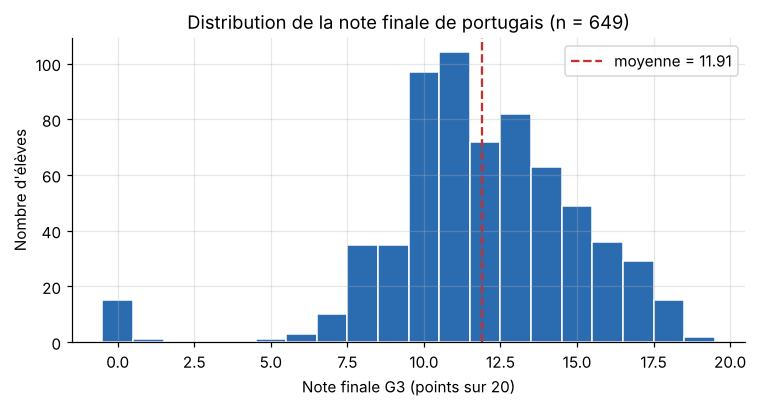

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(df.G3, bins=np.arange(-0.5, 20.5, 1), color="#2b6cb0", edgecolor="white")
ax.axvline(df.G3.mean(), color="#c53030", ls="--", label=f"moyenne = {df.G3.mean():.2f}")
ax.set_xlabel("Note finale G3 (points sur 20)"); ax.set_ylabel("Nombre d'élèves")
ax.set_title("Distribution de la note finale de portugais (n = 649)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig1_distribution_g3.png"); plt.show()

**Lecture de la figure 1.** La distribution est centrée autour de 11-12 avec une asymétrie vers les basses notes : une queue gauche et un pic isolé à 0 (15 élèves). La moyenne (11,91) sert de référence naïve. Les zéros ne sont pas des erreurs de saisie mais des abandons, donc ils sont gardés ; ils pèseront lourd dans toute métrique quadratique comme la RMSE.

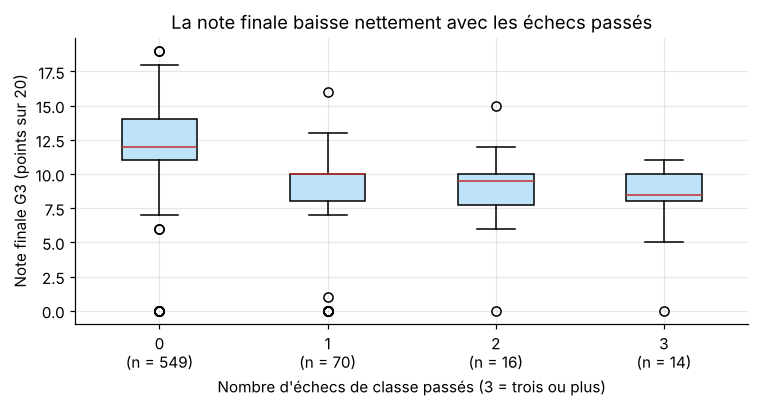

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.8))
groupes = [df.loc[df.failures == k, "G3"] for k in sorted(df.failures.unique())]
ax.boxplot(groupes, tick_labels=[f"{k}\n(n = {len(g)})" for k, g in zip(sorted(df.failures.unique()), groupes)], patch_artist=True,
           boxprops=dict(facecolor="#bee3f8"), medianprops=dict(color="#c53030"))
ax.set_xlabel("Nombre d'échecs de classe passés (3 = trois ou plus)"); ax.set_ylabel("Note finale G3 (points sur 20)")
ax.set_title("La note finale baisse nettement avec les échecs passés")
fig.tight_layout(); fig.savefig(FIG / "fig2_g3_par_echecs.png"); plt.show()

**Lecture de la figure 2.** La note médiane baisse à mesure que le nombre d'échecs passés augmente : les élèves sans échec ont une moyenne de 12,51 contre environ 8,1 pour ceux qui en ont trois ou plus (voir tableau ci-dessus). `failures` est la variable la plus liée à G3 (corrélation de -0,39) : l'historique d'échec est un bon signal d'alerte à la rentrée. Les groupes à 2 et 3 échecs sont très petits (16 et 14 élèves), donc ces moyennes sont fragiles.

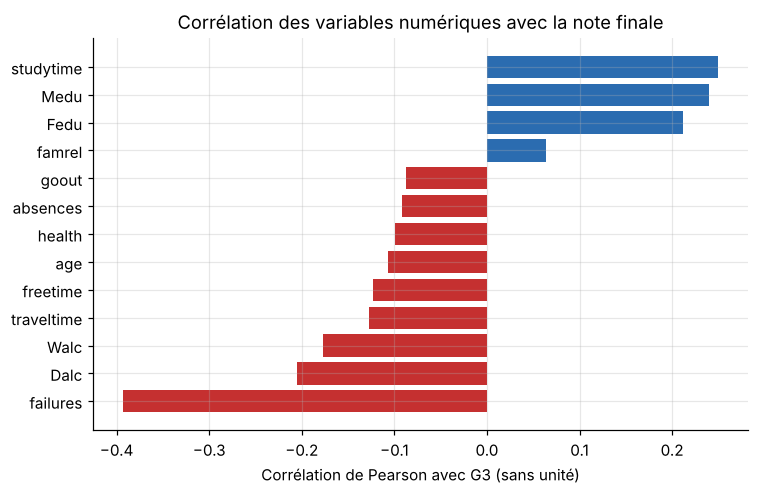

In [7]:
num_cols = df.select_dtypes("number").columns.drop(["G1", "G2", "G3"])
corr = df[num_cols].corrwith(df["G3"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(corr.index, corr.values, color=np.where(corr.values < 0, "#c53030", "#2b6cb0"))
ax.set_xlabel("Corrélation de Pearson avec G3 (sans unité)"); ax.set_title("Corrélation des variables numériques avec la note finale")
fig.tight_layout(); fig.savefig(FIG / "figA1_correlations.png"); plt.show()
RES["corr_failures"] = float(corr["failures"]); RES["corr_studytime"] = float(corr["studytime"]); RES["corr_absences"] = float(corr["absences"])

**Lecture du graphique 3 (annexe).** Les liens linéaires sont faibles à modérés : le plus fort est `failures` (-0,39), puis `studytime` (+0,25), `Medu` (+0,24) et la consommation d'alcool en semaine (-0,21). Aucune variable ne domine, ce qui annonce un problème difficile : la part de variance expliquée sera modeste.

## 4. Préparation

- **Nettoyage** : aucun traitement de valeurs manquantes ni de doublons (il n'y en a pas). Les valeurs extrêmes sont conservées (section 3).
- **Variables créées** : aucune ; les 30 variables de profil sont utilisées telles quelles.
- **Variables exclues** : `G1` et `G2` (notes des deux premières périodes). Elles ne sont pas connues à la rentrée, moment de la décision d'allocation, et expliquent à elles seules l'essentiel de G3 (corrélation 0,83 et 0,92) : les inclure répondrait à une autre question (prévision en cours d'année) et donnerait des scores flatteurs. La documentation du jeu note elle aussi que prévoir G3 sans G1 et G2 est plus difficile mais bien plus utile. `absences` est conservée par choix : l'absentéisme de l'année n'est pas connu à la rentrée, c'est donc une limite (section 8) ; le modèle reste utilisable en début de 2e période, une fois l'assiduité observée.
- **Encodage et mise à l'échelle** : les 17 variables catégorielles sont encodées en indicatrices (`OneHotEncoder`). Aucune mise à l'échelle pour la forêt aléatoire, car les arbres ne dépendent pas de l'échelle des variables. Elle est en revanche appliquée (`StandardScaler`) pour le Ridge de comparaison, dont la pénalité dépend de l'échelle.
- **Découpage** : jeu aléatoire 80 % apprentissage / 20 % test (graine 42), car les données ne sont pas datées (pas d'ordre chronologique à respecter). Validation croisée à 5 plis sur l'apprentissage seulement.

**Prévention des fuites.**
- [x] Transformations ajustées sur l'apprentissage seulement, dans un `Pipeline` + `ColumnTransformer`.
- [x] Pas de découpage chronologique requis : données transversales sans date.
- [x] Variables construites sans information future : aucune variable créée ; G1 et G2 exclues.
- [x] Aucune variable ne contient la cible, même indirectement (G1 et G2 sont les notes des périodes précédentes de la même matière, donc retirées).
- [x] Jeu de test utilisé une seule fois, à la fin.

In [8]:
# Alignement : variables explicatives (extraits) et cible, sans G1/G2
X = df.drop(columns=["G1", "G2", "G3"])
y = df["G3"]
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
print(len(cat_cols), "variables catégorielles,", len(num_cols), "numériques ;", X.shape[1], "variables explicatives au total")
print("G1/G2/G3 dans X ?", [c for c in ("G1", "G2", "G3") if c in X.columns])
display(pd.concat([X[["school", "age", "failures", "absences", "higher"]], y], axis=1).head(4))

# Découpage : la graine est fixée, le test n'est touché qu'une fois, plus bas
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=GRAINE)
print("Apprentissage :", Xtr.shape, "| Test :", Xte.shape)
RES["n_train"], RES["n_test"] = len(Xtr), len(Xte)
pd.concat([Xtr, ytr], axis=1).to_csv(PROC / "train.csv", index=True)
pd.concat([Xte, yte], axis=1).to_csv(PROC / "test.csv", index=True)

prep_rf = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols), ("num", "passthrough", num_cols)])
prep_ridge = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols), ("num", StandardScaler(), num_cols)])

17 variables catégorielles, 13 numériques ; 30 variables explicatives au total
G1/G2/G3 dans X ? []


,school,age,failures,absences,higher,G3
0,GP,18,0,4,yes,11
1,GP,17,0,2,yes,11
2,GP,15,0,6,yes,12
3,GP,15,0,0,yes,14


Apprentissage : (519, 30) | Test : (130, 30)


## 5. Algorithme

**Choix.** Forêt aléatoire en régression (n° 6 de l'annexe A, `RandomForestRegressor`). Les profils d'élèves mêlent beaucoup de variables catégorielles et ordinales dont les effets sont probablement non linéaires et en interaction (par exemple échecs passés et souhait d'études supérieures) ; une forêt les capte sans spécification manuelle et reste robuste avec 649 observations. Cortez et Silva (2008) comparent d'ailleurs la forêt aléatoire à d'autres modèles sur ce même jeu. **Alternative plausible écartée** : l'arbre de régression unique (n° 5), instable (forte variance) sur un petit jeu bruité. Le Ridge (n° 2) est gardé comme comparaison facultative, pas comme algorithme principal ; le gradient boosting (n° 7) a été écarté car il demande plus de réglages et surapprend plus facilement sur un jeu aussi petit et bruité.

**Principe.** On construit 300 arbres de régression, chacun entraîné sur un échantillon bootstrap de l'apprentissage, et à chaque scission seul un sous-ensemble aléatoire de variables est considéré. La prédiction est la **moyenne** des prédictions des arbres. Moyenner des arbres peu corrélés réduit la variance sans augmenter le biais. Implémentation : scikit-learn (Pedregosa et al., 2011).

**Formule essentielle.**
$$\hat y(x)=\frac{1}{B}\sum_{b=1}^{B} T_b(x)$$
où $\hat y(x)$ est la note prédite pour l'élève de profil $x$, $B=300$ le nombre d'arbres, et $T_b(x)$ la prédiction de l'arbre $b$, égale à la moyenne de G3 des élèves d'apprentissage tombés dans la même feuille que $x$.

**Paramètres appris.** Pour chaque arbre : les variables et seuils de chaque scission, et la valeur moyenne de chaque feuille. Les hyperparamètres (profondeur, taille des feuilles, nombre d'arbres) ne sont pas appris mais fixés.

**Hyperparamètres étudiés.**

| Hyperparamètre | Rôle et effet attendu | Valeurs testées | Valeur retenue |
| --- | --- | --- | --- |
| `max_depth` | Profondeur maximale d'un arbre : plus elle est grande, plus le modèle est flexible et risque de surapprendre | 3, 5, 8, aucune limite | 8 |
| `min_samples_leaf` | Nombre minimal d'élèves par feuille : plus il est grand, plus les prédictions sont lissées | 1, 5, 10, 20 | 10 |

(`n_estimators` = 300 est fixé, `random_state` = 42.)

## 6. Protocole expérimental

- **Découpage** : apprentissage 519 élèves (80 %), test 130 élèves (20 %), tirage aléatoire de graine 42. Validation croisée à 5 plis (`KFold`, mélange, graine 42) sur l'apprentissage ; il n'y a pas d'ensemble de validation séparé.
- **Référence naïve** : prédire la moyenne de G3 de l'apprentissage pour tous les élèves (`DummyRegressor(strategy="mean")`). C'est la règle sans information du tableau de l'énoncé pour une régression sans dimension temporelle.
- **Validation / réglage** : `GridSearchCV` à 5 plis sur l'apprentissage, **16 configurations** (4 profondeurs × 4 tailles de feuille). Pour le Ridge de comparaison : 5 valeurs de $\alpha$.
- **Métrique principale** : RMSE (racine de l'erreur quadratique moyenne), en points de note sur 20 ; elle pénalise les grosses erreurs, donc les abandons mal prévus, ce qui correspond au risque suivi. **Secondaires** : MAE (erreur absolue moyenne, en points) et $R^2$ (part de variance expliquée ; 0 pour la référence).
- **Graine aléatoire** : 42.

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=GRAINE)

# Référence naïve
base = Pipeline([("m", DummyRegressor(strategy="mean"))])
sc_base = -cross_val_score(base, Xtr, ytr, cv=cv, scoring="neg_root_mean_squared_error")
RES["base_cv_mean"], RES["base_cv_std"] = float(sc_base.mean()), float(sc_base.std())

# Forêt aléatoire : 16 configurations
rf = Pipeline([("prep", prep_rf), ("m", RandomForestRegressor(n_estimators=300, random_state=GRAINE, n_jobs=-1))])
grille = {"m__max_depth": [3, 5, 8, None], "m__min_samples_leaf": [1, 5, 10, 20]}
gs = GridSearchCV(rf, grille, cv=cv, scoring="neg_root_mean_squared_error", return_train_score=True).fit(Xtr, ytr)
i = gs.best_index_
RES["rf_best_params"] = {k.replace("m__", ""): (None if v is None else int(v)) for k, v in gs.best_params_.items()}
RES["rf_cv_mean"], RES["rf_cv_std"] = float(-gs.best_score_), float(gs.cv_results_["std_test_score"][i])
RES["n_configs"] = int(len(gs.cv_results_["params"]))

# Ridge de comparaison
ridge = Pipeline([("prep", prep_ridge), ("m", Ridge())])
gr = GridSearchCV(ridge, {"m__alpha": [1, 10, 30, 100, 300]}, cv=cv, scoring="neg_root_mean_squared_error").fit(Xtr, ytr)
RES["ridge_alpha"] = float(gr.best_params_["m__alpha"])
RES["ridge_cv_mean"], RES["ridge_cv_std"] = float(-gr.best_score_), float(gr.cv_results_["std_test_score"][gr.best_index_])

print("Référence (moyenne)   : RMSE validation = %.3f ± %.3f" % (RES["base_cv_mean"], RES["base_cv_std"]))
print("Forêt aléatoire       : RMSE validation = %.3f ± %.3f | meilleurs paramètres : %s" % (RES["rf_cv_mean"], RES["rf_cv_std"], RES["rf_best_params"]))
print("Ridge (comparaison)   : RMSE validation = %.3f ± %.3f | alpha = %g" % (RES["ridge_cv_mean"], RES["ridge_cv_std"], RES["ridge_alpha"]))
print("Configurations essayées pour la forêt :", RES["n_configs"], "| pour le Ridge : 5")

Référence (moyenne)   : RMSE validation = 3.233 ± 0.391
Forêt aléatoire       : RMSE validation = 2.659 ± 0.327 | meilleurs paramètres : {'max_depth': 8, 'min_samples_leaf': 10}
Ridge (comparaison)   : RMSE validation = 2.753 ± 0.314 | alpha = 100
Configurations essayées pour la forêt : 16 | pour le Ridge : 5


## 7. Résultats

Le jeu de test n'est utilisé qu'à partir d'ici, une seule fois pour chaque modèle déjà réglé.

In [10]:
best = gs.best_estimator_
base.fit(Xtr, ytr)
modeles = {"Référence (moyenne de G3)": base, "Forêt aléatoire": best, "Ridge (comparaison)": gr.best_estimator_}
lignes = []
for nom, m in modeles.items():
    p_te, p_tr = m.predict(Xte), m.predict(Xtr)
    lignes.append({"Modèle": nom, "RMSE apprentissage": rmse(ytr, p_tr),
                   "RMSE test": rmse(yte, p_te), "MAE test": mean_absolute_error(yte, p_te), "R² test": r2_score(yte, p_te)})
tab = pd.DataFrame(lignes).set_index("Modèle")
tab["RMSE validation (5 plis)"] = [RES["base_cv_mean"], RES["rf_cv_mean"], RES["ridge_cv_mean"]]
tab["± écart-type"] = [RES["base_cv_std"], RES["rf_cv_std"], RES["ridge_cv_std"]]
display(tab.round(3))
RES["test"] = {k: {c: float(v) for c, v in r.items()} for k, r in tab.rename(index={"Référence (moyenne de G3)": "base", "Forêt aléatoire": "rf", "Ridge (comparaison)": "ridge"}).iterrows()}
gain = 100 * (1 - tab.loc["Forêt aléatoire", "RMSE test"] / tab.loc["Référence (moyenne de G3)", "RMSE test"])
RES["gain_rmse_pct"] = float(gain); RES["objectif_atteint"] = bool(gain >= 10)
gain_ridge = 100 * (1 - tab.loc["Ridge (comparaison)", "RMSE test"] / tab.loc["Référence (moyenne de G3)", "RMSE test"])
RES["gain_ridge_pct"] = float(gain_ridge)
print(f"Gain de RMSE de la forêt sur la référence (test) : {gain:.1f} %  -> objectif (>= 10 %) {'ATTEINT' if gain >= 10 else 'NON atteint'}")
print(f"Gain de RMSE du Ridge sur la référence (test)    : {gain_ridge:.1f} %")

,RMSE apprentissage,RMSE test,MAE test,R² test,RMSE validation (5 plis),± écart-type
Modèle,,,,,,
Référence (moyenne de G3),3.244,3.173,2.395,-0.032,3.233,0.391
Forêt aléatoire,2.274,2.813,2.057,0.189,2.659,0.327
Ridge (comparaison),2.595,2.775,2.026,0.210,2.753,0.314


Gain de RMSE de la forêt sur la référence (test) : 11.3 %  -> objectif (>= 10 %) ATTEINT
Gain de RMSE du Ridge sur la référence (test)    : 12.5 %


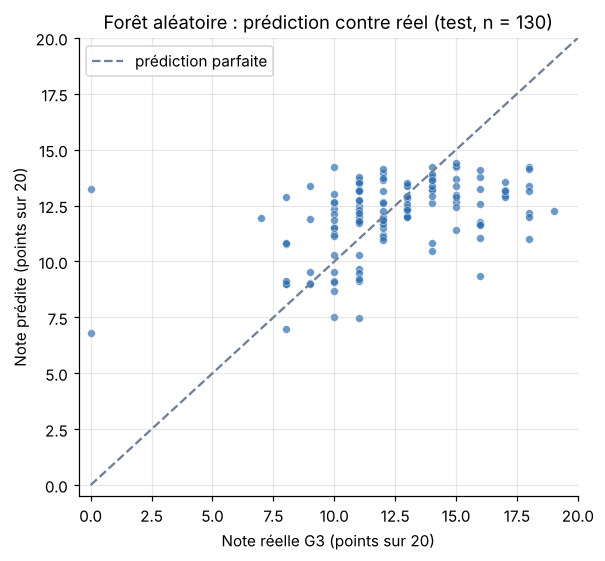

In [11]:
p = best.predict(Xte)
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(yte, p, s=26, alpha=.7, color="#2b6cb0", edgecolor="white", linewidth=.4)
ax.plot([0, 20], [0, 20], "--", color="#718096", label="prédiction parfaite")
ax.set_xlim(-0.5, 20); ax.set_ylim(-0.5, 20)
ax.set_xlabel("Note réelle G3 (points sur 20)"); ax.set_ylabel("Note prédite (points sur 20)")
ax.set_title("Forêt aléatoire : prédiction contre réel (test, n = 130)"); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "fig3_prediction_vs_reel.png"); plt.show()
RES["pred_min"], RES["pred_max"] = float(p.min()), float(p.max())

**Lecture de la figure 3.** Les prédictions forment un nuage aplati autour de la diagonale : le modèle prédit des notes comprises entre 7 et 14 environ et ne descend jamais près de 0. Il « tire vers la moyenne » : les élèves très faibles sont surestimés, les très bons sous-estimés. L'ordre relatif des élèves est en partie préservé, utile pour un classement par risque, mais la valeur exacte de la note est incertaine.

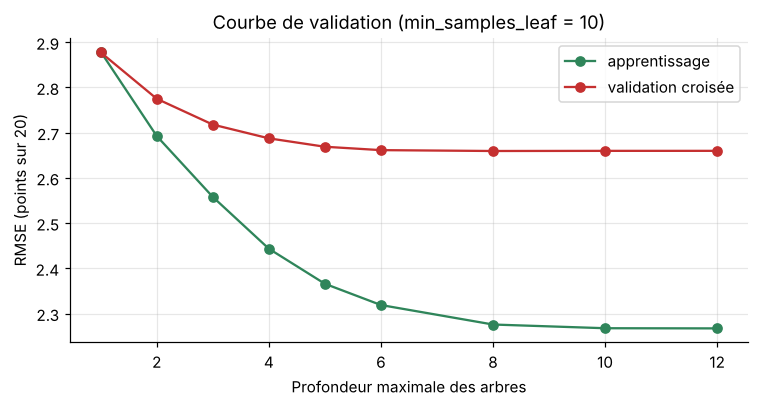

 profondeur  RMSE apprentissage  RMSE validation
          1               2.879            2.878
          2               2.692            2.775
          3               2.558            2.718
          4               2.443            2.687
          5               2.366            2.669
          6               2.319            2.661
          8               2.276            2.659
         10               2.267            2.660
         12               2.267            2.660


In [12]:
# Courbe de validation : effet de la profondeur (min_samples_leaf fixé à la valeur retenue)
prof = [1, 2, 3, 4, 5, 6, 8, 10, 12]
rf_vc = Pipeline([("prep", prep_rf), ("m", RandomForestRegressor(n_estimators=300, random_state=GRAINE, n_jobs=-1,
                                                                  min_samples_leaf=RES["rf_best_params"]["min_samples_leaf"]))])
tr, va = validation_curve(rf_vc, Xtr, ytr, param_name="m__max_depth", param_range=prof, cv=cv, scoring="neg_root_mean_squared_error")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(prof, -tr.mean(1), "o-", label="apprentissage", color="#2f855a")
ax.plot(prof, -va.mean(1), "o-", label="validation croisée", color="#c53030")
ax.set_xlabel("Profondeur maximale des arbres"); ax.set_ylabel("RMSE (points sur 20)")
ax.set_title("Courbe de validation (min_samples_leaf = %d)" % RES["rf_best_params"]["min_samples_leaf"]); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig4_courbe_validation.png"); plt.show()
RES["vc"] = {"profondeur": prof, "train": [float(v) for v in -tr.mean(1)], "val": [float(v) for v in -va.mean(1)]}
print(pd.DataFrame({"profondeur": prof, "RMSE apprentissage": (-tr.mean(1)).round(3), "RMSE validation": (-va.mean(1)).round(3)}).to_string(index=False))

**Lecture de la courbe de validation.** L'erreur d'apprentissage continue de baisser avec la profondeur alors que l'erreur de validation se stabilise à partir d'une profondeur de 6 à 8 puis ne s'améliore plus : au-delà, la forêt mémorise l'apprentissage sans mieux généraliser. Le choix de `max_depth` = 8 (avec `min_samples_leaf` = 10) est cohérent avec ce plateau.

In [13]:
# Analyse des erreurs : par tranche de note réelle, et cas les plus mal prédits
err = pd.DataFrame({"reel": yte.values, "pred": p, "base": base.predict(Xte)}, index=yte.index)
err["erreur"] = err.pred - err.reel
err["tranche"] = pd.cut(err.reel, [-1, 0, 9, 13, 20], labels=["0 (abandon)", "1 à 9", "10 à 13", "14 à 20"])
par_tr = err.groupby("tranche", observed=True).agg(n=("reel", "size"), rmse=("erreur", lambda e: (e**2).mean() ** .5), biais=("erreur", "mean"))
display(par_tr.round(2))
RES["err_tranche"] = {str(k): {"n": int(v["n"]), "rmse": float(v["rmse"]), "biais": float(v["biais"])} for k, v in par_tr.iterrows()}
masque = yte > 0
RES["rmse_sans_zero"] = float(rmse(yte[masque], p[masque])); RES["base_rmse_sans_zero"] = float(rmse(yte[masque], err.base[masque]))
RES["n_zero_test"] = int((yte == 0).sum())
print("RMSE test sans les élèves à G3 = 0 : forêt %.3f | référence %.3f (n zéros dans le test : %d)" % (RES["rmse_sans_zero"], RES["base_rmse_sans_zero"], RES["n_zero_test"]))
display(err.reindex(err.erreur.abs().sort_values(ascending=False).index).head(5).round(2)[["reel", "pred", "erreur"]])

,n,rmse,biais
tranche,,,
0 (abandon),2,10.54,10.04
1 à 9,13,2.73,1.96
10 à 13,71,1.58,0.56
14 à 20,44,3.48,-2.87


RMSE test sans les élèves à G3 = 0 : forêt 2.510 | référence 2.837 (n zéros dans le test : 2)


,reel,pred,erreur
603,0,13.25,13.25
549,18,11.02,-6.98
163,0,6.82,6.82
636,19,12.28,-6.72
212,16,9.36,-6.64


In [14]:
# Illustration d'usage : 5 élèves du test (ordre du jeu, sans tri sur le résultat)
ill = Xte.iloc[[0, 1, 2, 3, 4]][["school", "age", "failures", "absences", "higher"]].copy()
ill["Prédiction"] = p[:5].round(1); ill["Valeur réelle"] = yte.iloc[:5].values
ill["Écart"] = (ill["Prédiction"] - ill["Valeur réelle"]).round(1)
display(ill)
RES["illustration"] = [{"id": int(i), "school": r["school"], "age": int(r["age"]), "failures": int(r["failures"]), "absences": int(r["absences"]),
                        "higher": r["higher"], "pred": float(r["Prédiction"]), "reel": float(r["Valeur réelle"])} for i, r in ill.iterrows()]

,school,age,failures,absences,higher,Prédiction,Valeur réelle,Écart
636,MS,18,0,4,yes,12.3,19,-6.7
220,GP,16,0,2,yes,12.6,12,0.6
594,MS,18,0,0,yes,13.4,18,-4.6
429,MS,16,0,5,yes,12.0,11,1.0
72,GP,15,0,2,yes,11.8,11,0.8


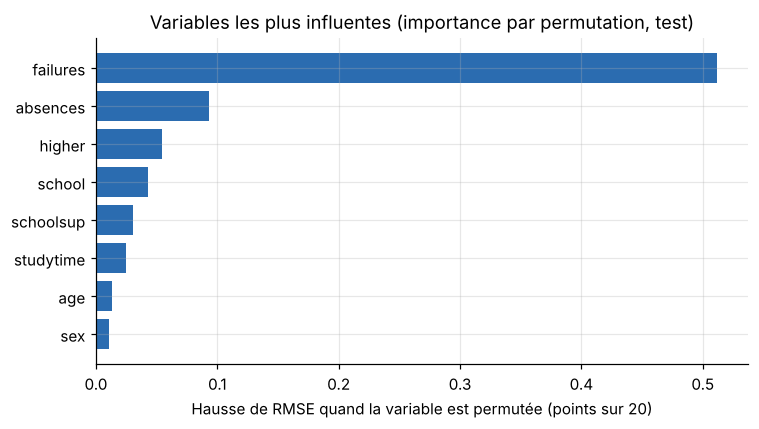

failures     0.512
absences     0.093
higher       0.054
school       0.043
schoolsup    0.031
studytime    0.025
age          0.013
sex          0.011


In [15]:
# Importance par permutation (sur le test) : hausse de RMSE quand une variable est mélangée
pi = permutation_importance(best, Xte, yte, n_repeats=20, random_state=GRAINE, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
top = imp.head(8)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top.values, color="#2b6cb0")
ax.set_xlabel("Hausse de RMSE quand la variable est permutée (points sur 20)"); ax.set_title("Variables les plus influentes (importance par permutation, test)")
fig.tight_layout(); fig.savefig(FIG / "fig5_importance_permutation.png"); plt.show()
RES["importance"] = {k: float(v) for k, v in imp.head(8).items()}
print(imp.head(8).round(3).to_string())

In [16]:
# Stabilité : 5 autres découpages (graines 0 à 4), mêmes hyperparamètres, test propre à chaque graine
stab = []
for s in range(5):
    a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=s)
    m = Pipeline([("prep", prep_rf), ("m", RandomForestRegressor(n_estimators=300, random_state=s, n_jobs=-1,
                  max_depth=RES["rf_best_params"]["max_depth"], min_samples_leaf=RES["rf_best_params"]["min_samples_leaf"]))]).fit(a, c)
    r_rf, r_b = rmse(d, m.predict(b)), rmse(d, np.full(len(d), c.mean()))
    stab.append({"graine": s, "RMSE forêt": r_rf, "RMSE référence": r_b, "gain (%)": 100 * (1 - r_rf / r_b)})
stab = pd.DataFrame(stab); display(stab.round(3))
RES["stab"] = stab.round(4).to_dict("records")
RES["stab_gain_min"], RES["stab_gain_max"], RES["stab_gain_mean"] = float(stab["gain (%)"].min()), float(stab["gain (%)"].max()), float(stab["gain (%)"].mean())

,graine,RMSE forêt,RMSE référence,gain (%)
0,0,2.375,2.681,11.416
1,1,3.180,3.665,13.230
2,2,2.899,3.488,16.894
3,3,2.497,2.939,15.038
4,4,2.956,3.424,13.650


**Lecture des résultats.** Sur le test (130 élèves), la forêt aléatoire obtient une RMSE de 2,81 points contre 3,17 pour la moyenne, soit une baisse de 11,3 %, et une MAE de 2,06 contre 2,39. Le $R^2$ n'est que de 0,19 : le modèle explique moins d'un cinquième de la variance de G3 (la référence est à -0,03, comme attendu pour une moyenne évaluée sur un autre échantillon). En validation croisée, la RMSE est de 2,66 ± 0,33 contre 3,23 ± 0,39 pour la référence. Le **Ridge** fait aussi bien, voire un peu mieux : 2,78 de RMSE test et un $R^2$ de 0,21. Les deux modèles sont donc proches, et l'avantage éventuel du Ridge (2,78 contre 2,81) est bien inférieur à l'écart-type de validation, donc non significatif.

**Analyse des erreurs.** L'erreur est très inégale selon le niveau réel : les deux élèves à G3 = 0 du test sont prédits en moyenne à 10 points au-dessus de leur note réelle, et dominent la RMSE ; en les écartant, la RMSE de la forêt passe de 2,81 à 2,51. Plus largement, le modèle surestime les élèves faibles et sous-estime les meilleurs (régression vers la moyenne), comme le montrent les biais par tranche ci-dessus.

**Illustration d'usage.** Le tableau ci-dessus donne cinq élèves du test, pris dans l'ordre du jeu, avec leur prédiction et leur note réelle. Trois élèves sur cinq sont prédits à moins de 1 point près, mais les deux meilleurs élèves du lot (19 et 18) sont sous-estimés de 7 et 4,6 points : cohérent avec la régression vers la moyenne. Suffisant pour classer des profils par risque, pas pour prédire une note précise.

## 8. Analyse critique

**Réponse à l'objectif.** L'objectif fixé (RMSE inférieure d'au moins 10 % à celle de la référence) est **atteint**, mais de justesse : 11,3 % sur le test, et entre 11 % et 17 % sur cinq autres découpages (graines 0 à 4), donc le gain est stable. Il est modeste en valeur absolue ($R^2$ = 0,19).

**Interprétation.** L'importance par permutation désigne `failures` comme variable très largement dominante (hausse de RMSE d'environ 0,51 point lorsqu'elle est mélangée), loin devant `absences` (0,09), `higher` (0,05) et `school` (0,04). Ce sont des associations, pas des causes : `schoolsup` (soutien scolaire) apparaît parmi les variables influentes, mais les élèves qui reçoivent un soutien sont ceux déjà en difficulté, d'où un lien négatif apparent qui ne dit rien de l'efficacité du soutien. Cela souligne aussi la limite pour une décision d'allocation : le modèle repère qui est en difficulté, pas à qui le soutien profitera le plus.

**Surapprentissage et généralisation.** La RMSE d'apprentissage (2,27) est inférieure à celle du test (2,81) : l'écart d'environ 0,5 point indique un surapprentissage modéré, contenu par `max_depth` et `min_samples_leaf`. Le gain est stable sur cinq découpages différents, ce qui plaide pour une généralisation correcte à l'intérieur de ces deux établissements.

**Comparaison avec les travaux liés.** Cortez et Silva (2008) obtiennent une bien meilleure précision quand G1 et G2 sont utilisées, et la documentation du jeu indique que sans elles la prévision est nettement plus difficile ; notre résultat (RMSE de 2,81, $R^2$ de 0,19, sans G1 ni G2) va dans ce sens et le confirme.

**Limites et biais.** (1) Deux établissements portugais, une seule année scolaire : pas de généralisation à d'autres contextes. (2) Variables déclaratives (alcool, temps libre), sujettes à biais de réponse. (3) `absences` n'est connue qu'en fin d'année : en toute rigueur, le modèle à la rentrée ne devrait pas l'utiliser. (4) Le jeu de test (130 élèves, dont 2 abandons) est petit, donc les chiffres sont bruités ; les hyperparamètres ont été réglés sur un seul découpage, et les autres graines réutilisent une partie de ces données, d'où un léger optimisme. (5) Pas de coût de décision : se tromper sur un élève à risque ne coûte pas autant que l'inverse, ce que la RMSE ne reflète pas.

**Pistes d'amélioration.** (1) Transformer le problème en classification de l'échec (G3 < 10) avec un seuil de décision choisi selon le coût de manquer un élève à risque, plus proche de la décision d'allocation. (2) Ajouter G1 dès que la première période est évaluée, pour un modèle d'alerte en cours d'année, et comparer le gain.

## 9. Conclusion

Sans utiliser les notes des périodes précédentes, une forêt aléatoire prévoit la note finale de portugais avec une RMSE de 2,81 points sur 20 sur le test, contre 3,17 pour la simple moyenne (gain de 11,3 %, objectif de 10 % atteint, stable sur cinq découpages), mais avec un $R^2$ de 0,19 seulement : le modèle sert à repérer des profils à risque, surtout via les échecs passés, pas à prédire une note précise. Perspective : passer à une classification de l'échec avec un seuil lié au coût de la décision, et ajouter G1 en cours d'année.

## 10. Références et reproduction

[1] P. Cortez, *Student Performance* [jeu de données], UCI Machine Learning Repository, 2014, DOI 10.24432/C5TG7T, https://archive.ics.uci.edu/dataset/320/student+performance (consulté le 24/11/2026).
[2] P. Cortez et A. Silva, « Using data mining to predict secondary school student performance », *Proceedings of 5th Future Business Technology Conference (FUBUTEC 2008)*, p. 5-12, 2008.
[3] F. Pedregosa *et al.*, « Scikit-learn : Machine Learning in Python », *Journal of Machine Learning Research*, vol. 12, p. 2825-2830, 2011.
[4] Support du cours BD & DS, notebook `Tp_ML.ipynb`, ENCG-2026.

**Reproduction** : cloner le dépôt, `pip install -r requirements.txt`, ouvrir `notebooks/projet_student_performance.ipynb` et lancer « Redémarrer et tout exécuter » (quelques secondes à une minute). Tous les chemins sont relatifs ; graine = 42.

In [17]:
# Sauvegarde des chiffres cités dans le rapport et les diapositives
RES["python"] = sys.version.split()[0]; RES["sklearn"] = sklearn.__version__
with open(ROOT / "docs" / "resultats.json", "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=2)
print("docs/resultats.json écrit")

docs/resultats.json écrit


## Déclaration des ressources et outils d'IA

| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| Assistant d'IA (Claude, Anthropic) | 24/11/2026 | Rédaction du code du notebook, du texte du compte rendu, du rapport LaTeX, des diapositives et de la structure du dépôt, à partir de l'énoncé et du jeu de données fournis | Tout le projet | Notebook exécuté de bout en bout, chiffres du texte comparés aux sorties (`docs/resultats.json`) ; à relire et à défendre par l'étudiante |
| Documentation scikit-learn, pandas, matplotlib | 2026 | Syntaxe des fonctions | Notebook, sections 4 à 7 | Appels testés à l'exécution |
| Page UCI du jeu de données | consultée le 24/11/2026 | Source, licence, citation | Section 2 | Lien et licence relus sur la page |